# Revisão metodológica e análises de segurança viária (2022–2025)

Este notebook complementa as análises do projeto com dados do Infosiga-SP para Campinas e Guarulhos. As transformações e tabelas são feitas com Polars; a interface Pandas é usada apenas para tabelas de contingência e ajuste do modelo estatístico. Cada tabela preserva sua unidade de análise: sinistro, vítima ou veículo agregado por sinistro.

**Interpretação:** os resultados descrevem associações nos registros disponíveis e não estimam efeitos causais nem risco populacional. Contagens e proporções entre registros não substituem taxas com denominadores de exposição (por exemplo, população, frota ou quilometragem).

**Execução:** abra o notebook com `notebooks` como diretório de trabalho. As bases são lidas de `notebooks/dados`; para as tabelas recentes, o ano de 2025 é selecionado e 2026 é excluído.

## 1. Preparação das bases e escopo

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from scipy import stats
from statsmodels.formula.api import glm
from statsmodels.genmod.families import Binomial
from statsmodels.stats.proportion import proportion_confint

ANOS_ANALISE = [2022, 2023, 2024, 2025]
MUNICIPIOS_ANALISE = ["CAMPINAS", "GUARULHOS"]
VALOR_DESCONHECIDO = "NAO INFORMADO"
PASTA_DADOS = Path("dados") if Path("dados").exists() else Path("notebooks/dados")

def ler_base(nome_base: str) -> pl.DataFrame:
    """Lê as bases 2022–2024 e acrescenta somente os registros de 2025."""
    base_2022_2024 = pl.read_csv(
        PASTA_DADOS / f"{nome_base}_2022-2024.csv",
        separator=";",
        encoding="latin-1",
        infer_schema_length=10_000,
    )
    base_2025_2026 = pl.read_csv(
        PASTA_DADOS / f"{nome_base}_2025-2026.csv",
        separator=";",
        encoding="latin-1",
        infer_schema_length=10_000,
    ).filter(pl.col("ano_sinistro").cast(pl.Int16, strict=False) == 2025)
    return pl.concat(
        [base_2022_2024, base_2025_2026], how="diagonal_relaxed"
    ).with_columns(pl.col("ano_sinistro").cast(pl.Int16, strict=False))

sinistros_fonte = ler_base("sinistros")
pessoas_fonte = ler_base("pessoas")
veiculos_fonte = ler_base("veiculos")

sinistros_escopo = sinistros_fonte.filter(
    pl.col("ano_sinistro").is_in(ANOS_ANALISE)
    & pl.col("municipio").is_in(MUNICIPIOS_ANALISE)
)
ids_sinistros_escopo = sinistros_escopo.select("id_sinistro").unique()
if sinistros_escopo.group_by("id_sinistro").len().filter(pl.col("len") > 1).height:
    raise ValueError("A base de sinistros possui id_sinistro duplicado no escopo.")

sinistros = sinistros_escopo.filter(pl.col("tipo_registro") != "NOTIFICACAO")
pessoas = pessoas_fonte.filter(
    pl.col("ano_sinistro").is_in(ANOS_ANALISE)
    & pl.col("municipio").is_in(MUNICIPIOS_ANALISE)
)
if "tipo_via" in pessoas.columns:
    pessoas = pessoas.drop("tipo_via")
colunas_sinistro_pessoa = [
    "id_sinistro", "tipo_registro", "tipo_via", "tp_sinistro_primario",
    "qtd_gravidade_fatal",
    "tp_sinistro_atrop_pedestre", "tp_sinistro_atrop_vitima_fora_veic",
    "tp_sinistro_colisao_frontal", "tp_sinistro_colisao_traseira",
    "tp_sinistro_colisao_lateral", "tp_sinistro_colisao_transversal",
    "tp_sinistro_capotamento", "tp_sinistro_tombamento",
]
sinistros_para_pessoas = sinistros_escopo.select(
    [coluna for coluna in colunas_sinistro_pessoa if coluna in sinistros_escopo.columns]
)
pessoas = pessoas.join(
    sinistros_para_pessoas,
    on="id_sinistro",
    how="left",
    validate="m:1",
    suffix="_sinistro",
)
veiculos = veiculos_fonte.filter(pl.col("ano_sinistro").is_in(ANOS_ANALISE)).join(
    ids_sinistros_escopo,
    on="id_sinistro",
    how="inner",
    validate="m:1",
)

print(f"Sinistros no escopo (inclui notificações): {sinistros_escopo.height:,}")
print(f"Sinistros analisáveis: {sinistros.height:,}")
print(f"Registros de vítimas no escopo: {pessoas.height:,}")
print(f"Registros de veículos no escopo: {veiculos.height:,}")

Sinistros no escopo (inclui notificações): 40,910
Sinistros analisáveis: 25,919
Registros de vítimas no escopo: 51,740
Registros de veículos no escopo: 46,054


## 2. Revisão das taxas e auditoria dos desfechos

### Proporções de fatalidade

A expressão usada em uma taxa deve ser conferida em relação ao significado do denominador. Se `total` já inclui os casos fatais, a fórmula original `fatalidades / (fatalidades + total)` conta os fatais duas vezes no denominador. Para proporção de sinistros fatais, a fórmula adequada é `sinistros fatais / total de sinistros elegíveis`; para proporção de vítimas fatais, é `vítimas fatais / total de vítimas elegíveis`, sempre na tabela de pessoas. Uma proporção de registros não é risco populacional.

In [2]:
total_sinistros = sinistros.height
sinistros_fatais = sinistros.filter(
    pl.col("tipo_registro") == "SINISTRO FATAL"
).height
total_vitimas_classificadas = pessoas.filter(
    pl.col("gravidade_lesao").is_in(["FATAL", "GRAVE", "LEVE", "ILESO"])
).height
vitimas_fatais = pessoas.filter(pl.col("gravidade_lesao") == "FATAL").height

validacao_taxas = pl.DataFrame(
    {
        "desfecho": ["Sinistro fatal", "Vítima fatal"],
        "fatalidades": [sinistros_fatais, vitimas_fatais],
        "denominador_elegivel": [total_sinistros, total_vitimas_classificadas],
        "percentual_corrigido": [
            100 * sinistros_fatais / total_sinistros if total_sinistros else None,
            100 * vitimas_fatais / total_vitimas_classificadas
            if total_vitimas_classificadas else None,
        ],
        "percentual_formula_original": [
            100 * sinistros_fatais / (sinistros_fatais + total_sinistros)
            if total_sinistros else None,
            100 * vitimas_fatais / (vitimas_fatais + total_vitimas_classificadas)
            if total_vitimas_classificadas else None,
        ],
    }
)
print(validacao_taxas)
print(
    "Problema: o denominador fatalidades + total duplica os casos fatais quando "
    "total já os contém. Correção: fatalidades / total elegível. "
    "Impacto: a estimativa original fica artificialmente menor; a correção "
    "altera a proporção descritiva, não cria uma medida de risco populacional."
)

shape: (2, 5)
┌────────────────┬─────────────┬──────────────────────┬──────────────────────┬─────────────────────┐
│ desfecho       ┆ fatalidades ┆ denominador_elegivel ┆ percentual_corrigido ┆ percentual_formula_ │
│ ---            ┆ ---         ┆ ---                  ┆ ---                  ┆ original            │
│ str            ┆ i64         ┆ i64                  ┆ f64                  ┆ ---                 │
│                ┆             ┆                      ┆                      ┆ f64                 │
╞════════════════╪═════════════╪══════════════════════╪══════════════════════╪═════════════════════╡
│ Sinistro fatal ┆ 1176        ┆ 25919                ┆ 4.537212             ┆ 4.340284            │
│ Vítima fatal   ┆ 1229        ┆ 48530                ┆ 2.532454             ┆ 2.469905            │
└────────────────┴─────────────┴──────────────────────┴──────────────────────┴─────────────────────┘
Problema: o denominador fatalidades + total duplica os casos fatais quando to

In [3]:
# Revisão automatizada de expressões candidatas nos notebooks do projeto.
# A inspeção deve ser confirmada manualmente porque variáveis como "total" podem
# ter definições diferentes em cada análise.
import re

padrao_formula = re.compile(
    r"(?:fatal|obit|morte).{0,80}/.{0,80}(?:fatal|obit|total)|"
    r"(?:fatal|obit|total).{0,80}/.{0,80}(?:fatal|obit)",
    re.IGNORECASE,
)
achados_formulas = []
for arquivo_notebook in Path(".").glob("*.ipynb"):
    try:
        conteudo_notebook = arquivo_notebook.read_text(encoding="utf-8")
    except OSError as erro:
        raise OSError(f"Não foi possível ler {arquivo_notebook}: {erro}") from erro
    for numero_linha, linha in enumerate(conteudo_notebook.splitlines(), start=1):
        if padrao_formula.search(linha):
            achados_formulas.append(
                {"arquivo": str(arquivo_notebook), "linha_json": numero_linha, "trecho": linha[:240]}
            )
print(pl.DataFrame(achados_formulas) if achados_formulas else "Nenhuma fórmula candidata encontrada; revisar manualmente células com taxas.")

shape: (28, 3)
┌─────────────────────────────────┬────────────┬─────────────────────────────────┐
│ arquivo                         ┆ linha_json ┆ trecho                          │
│ ---                             ┆ ---        ┆ ---                             │
│ str                             ┆ i64        ┆ str                             │
╞═════════════════════════════════╪════════════╪═════════════════════════════════╡
│ analise_exploratoria.ipynb      ┆ 145        ┆        "<small>shape: (10, 31)… │
│ analise_exploratoria_pessoas.i… ┆ 43         ┆        "<small>shape: (1, 31)<… │
│ analise_exploratoria_pessoas.i… ┆ 280        ┆        "<small>shape: (8, 4)</… │
│ analise_exploratoria_pessoas.i… ┆ 315        ┆     "        .with_columns((10… │
│ analise_exploratoria_pessoas.i… ┆ 335        ┆        "<small>shape: (8, 8)</… │
│ …                               ┆ …          ┆ …                               │
│ analise_metodologica_2022_2025… ┆ 156        ┆       "Problema: o deno

In [4]:
# Uma linha por sinistro na tabela de sinistros; uma linha por vítima na tabela de pessoas.
vitorias_por_sinistro = pessoas.with_columns(
    (pl.col("gravidade_lesao") == "FATAL").cast(pl.Int64).alias("vitima_fatal")
).group_by("id_sinistro").agg(
    pl.col("vitima_fatal").sum().alias("vitimas_fatais_pessoas"),
    (pl.col("data_obito").cast(pl.String, strict=False).is_not_null() & (pl.col("data_obito").cast(pl.String, strict=False) != "")).sum().alias("obitos_com_data"),
    (pl.col("tempo_sinistro_obito").cast(pl.String, strict=False).is_not_null() & (pl.col("tempo_sinistro_obito").cast(pl.String, strict=False) != "")).sum().alias("obitos_com_tempo"),
)
auditoria_desfechos = sinistros.select(
    "id_sinistro", "tipo_registro", "qtd_gravidade_fatal", "ano_sinistro", "municipio"
).join(vitorias_por_sinistro, on="id_sinistro", how="left", validate="1:1").with_columns(
    pl.col("vitimas_fatais_pessoas").fill_null(0),
    pl.col("obitos_com_data").fill_null(0),
    pl.col("obitos_com_tempo").fill_null(0),
    pl.col("qtd_gravidade_fatal").cast(pl.Int64, strict=False),
).with_columns(
    (pl.col("tipo_registro") == "SINISTRO FATAL").alias("registro_fatal"),
    (pl.col("qtd_gravidade_fatal").fill_null(0) > 0).alias("contagem_fatal_positiva"),
    (pl.col("vitimas_fatais_pessoas") > 0).alias("pessoa_fatal_encontrada"),
    ((pl.col("obitos_com_data") > 0) | (pl.col("obitos_com_tempo") > 0)).alias("evidencia_data_tempo_obito"),
).with_columns(
    (pl.col("registro_fatal") != pl.col("contagem_fatal_positiva")).alias("diverge_tipo_contagem"),
    (pl.col("registro_fatal") != pl.col("pessoa_fatal_encontrada")).alias("diverge_tipo_pessoa"),
    (pl.col("pessoa_fatal_encontrada") != pl.col("evidencia_data_tempo_obito")).alias("diverge_pessoa_data_tempo"),
    (pl.col("vitimas_fatais_pessoas") != pl.col("qtd_gravidade_fatal").fill_null(0)).alias("diverge_contagem_pessoas"),
)
colunas_divergencia = [
    "diverge_tipo_contagem", "diverge_tipo_pessoa",
    "diverge_pessoa_data_tempo", "diverge_contagem_pessoas",
]
resumo_auditoria = auditoria_desfechos.group_by("ano_sinistro").agg(
    pl.len().alias("sinistros"),
    *[pl.col(coluna).sum().alias(coluna) for coluna in colunas_divergencia],
)
print(resumo_auditoria.sort("ano_sinistro"))
print(
    auditoria_desfechos.filter(pl.any_horizontal([pl.col(c) for c in colunas_divergencia]))
    .select("id_sinistro", "ano_sinistro", "municipio", "tipo_registro", "qtd_gravidade_fatal", "vitimas_fatais_pessoas", "obitos_com_data", "obitos_com_tempo", *colunas_divergencia)
    .head(30)
)
print("As divergências são sinalizadores para revisão, não prova automática de erro: datas e tempos podem estar ausentes ou usar convenções distintas entre arquivos.")

shape: (4, 6)
┌──────────────┬───────────┬─────────────────┬─────────────────┬─────────────────┬─────────────────┐
│ ano_sinistro ┆ sinistros ┆ diverge_tipo_co ┆ diverge_tipo_pe ┆ diverge_pessoa_ ┆ diverge_contage │
│ ---          ┆ ---       ┆ ntagem          ┆ ssoa            ┆ data_tempo      ┆ m_pessoas       │
│ i16          ┆ u32       ┆ ---             ┆ ---             ┆ ---             ┆ ---             │
│              ┆           ┆ u32             ┆ u32             ┆ u32             ┆ u32             │
╞══════════════╪═══════════╪═════════════════╪═════════════════╪═════════════════╪═════════════════╡
│ 2022         ┆ 6652      ┆ 0               ┆ 0               ┆ 0               ┆ 0               │
│ 2023         ┆ 7001      ┆ 0               ┆ 0               ┆ 0               ┆ 0               │
│ 2024         ┆ 6946      ┆ 0               ┆ 0               ┆ 0               ┆ 0               │
│ 2025         ┆ 5320      ┆ 0               ┆ 0               ┆ 0           

## 3. Cobertura temporal e consistência entre tabelas

As bases de veículos não possuem município no arquivo. Por isso, sua contagem no escopo é obtida filtrando os identificadores de sinistros das cidades selecionadas, sem unir registros individuais de vítimas e veículos. As contagens de registros representam unidades diferentes e não devem ser comparadas como se fossem o mesmo denominador.

In [5]:
def tabela_cobertura(nome_base: str, base: pl.DataFrame, possui_municipio: bool) -> pl.DataFrame:
    linhas = []
    for ano in ANOS_ANALISE:
        base_ano = base.filter(pl.col("ano_sinistro") == ano)
        base_escopo = (
            base_ano.filter(pl.col("municipio").is_in(MUNICIPIOS_ANALISE))
            if possui_municipio
            else base_ano.join(ids_sinistros_escopo, on="id_sinistro", how="inner", validate="m:1")
        )
        linhas.append({
            "base": nome_base,
            "ano": ano,
            "registros_fonte": base_ano.height,
            "sinistros_unicos_fonte": base_ano["id_sinistro"].n_unique(),
            "registros_no_escopo": base_escopo.height,
            "sinistros_unicos_no_escopo": base_escopo["id_sinistro"].n_unique(),
        })
    return pl.DataFrame(linhas)

cobertura = pl.concat([
    tabela_cobertura("Sinistros", sinistros_fonte, True),
    tabela_cobertura("Pessoas", pessoas_fonte, True),
    tabela_cobertura("Veículos", veiculos_fonte, False),
]).sort(["base", "ano"])
print(cobertura)
print("O intervalo observado nesta análise vai de 2022 a 2025. O arquivo também contém 2026, deliberadamente excluído por não integrar o período definido.")

shape: (12, 6)
┌───────────┬──────┬─────────────────┬────────────────────┬────────────────────┬───────────────────┐
│ base      ┆ ano  ┆ registros_fonte ┆ sinistros_unicos_f ┆ registros_no_escop ┆ sinistros_unicos_ │
│ ---       ┆ ---  ┆ ---             ┆ onte               ┆ o                  ┆ no_escopo         │
│ str       ┆ i64  ┆ i64             ┆ ---                ┆ ---                ┆ ---               │
│           ┆      ┆                 ┆ i64                ┆ i64                ┆ i64               │
╞═══════════╪══════╪═════════════════╪════════════════════╪════════════════════╪═══════════════════╡
│ Pessoas   ┆ 2022 ┆ 266128          ┆ 132358             ┆ 13531              ┆ 6755              │
│ Pessoas   ┆ 2023 ┆ 279963          ┆ 142130             ┆ 13799              ┆ 7074              │
│ Pessoas   ┆ 2024 ┆ 273875          ┆ 137700             ┆ 13479              ┆ 7031              │
│ Pessoas   ┆ 2025 ┆ 211908          ┆ 102863             ┆ 10931           

## 4. Funções estatísticas e preparação dos desfechos

A análise de vulnerabilidade utiliza como desfecho vítima com lesão grave ou fatal. Registros sem classificação de gravidade não são imputados como desfecho negativo. Nas tabelas de contingência, o IC95% é de Wilson; os resíduos são ajustados e valores absolutos acima de 1,96 são referências exploratórias, sem correção automática para múltiplas comparações. O qui-quadrado é acompanhado da proporção de células com frequência esperada inferior a cinco.

In [6]:
COLUNAS_TIPO_DETALHADO = {
    "atropelamento": ["tp_sinistro_atrop_pedestre", "tp_sinistro_atrop_vitima_fora_veic"],
    "colisao_frontal": ["tp_sinistro_colisao_frontal"],
    "colisao_traseira": ["tp_sinistro_colisao_traseira"],
    "colisao_lateral": ["tp_sinistro_colisao_lateral"],
    "colisao_transversal": ["tp_sinistro_colisao_transversal"],
    "capotamento": ["tp_sinistro_capotamento"],
    "tombamento": ["tp_sinistro_tombamento"],
}

def texto_categorico(nome_coluna: str) -> pl.Expr:
    valor = pl.col(nome_coluna).cast(pl.String, strict=False).str.strip_chars().str.to_uppercase()
    return pl.when(valor.is_null() | valor.is_in(["", "NAO DISPONIVEL", "NÃO DISPONÍVEL"])) \
        .then(pl.lit(VALOR_DESCONHECIDO)).otherwise(valor)

def indicador_tipo(colunas: list[str]) -> pl.Expr:
    expressoes = [
        pl.col(coluna).cast(pl.String, strict=False).str.strip_chars().str.to_uppercase()
        .is_in(["S", "SIM", "1", "TRUE"]).fill_null(False)
        for coluna in colunas if coluna in pessoas.columns or coluna in sinistros.columns
    ]
    return pl.any_horizontal(expressoes) if expressoes else pl.lit(False)

idade = pl.col("idade").cast(pl.Float64, strict=False)
pessoas_analise = pessoas.with_columns(
    texto_categorico("modo_transporte_vitima").alias("modo_transporte_vitima"),
    texto_categorico("sexo").alias("sexo"),
    texto_categorico("municipio").alias("municipio"),
    texto_categorico("tipo_via").alias("tipo_via"),
    texto_categorico("gravidade_lesao").alias("gravidade_lesao"),
    idade.alias("idade_anos"),
).with_columns(
    pl.when(pl.col("idade_anos").is_between(0, 17)).then(pl.lit("00-17"))
    .when(pl.col("idade_anos").is_between(18, 29)).then(pl.lit("18-29"))
    .when(pl.col("idade_anos").is_between(30, 44)).then(pl.lit("30-44"))
    .when(pl.col("idade_anos").is_between(45, 59)).then(pl.lit("45-59"))
    .when(pl.col("idade_anos").is_between(60, 110)).then(pl.lit("60+"))
    .otherwise(pl.lit(VALOR_DESCONHECIDO)).alias("faixa_etaria_analise"),
    pl.when(pl.col("gravidade_lesao") == "FATAL").then(pl.lit(True))
    .when(pl.col("gravidade_lesao").is_in(["GRAVE", "LEVE", "ILESO"]))
    .then(pl.lit(False)).otherwise(None).alias("obito"),
    pl.when(pl.col("gravidade_lesao").is_in(["GRAVE", "FATAL"]))
    .then(pl.lit(True)).when(pl.col("gravidade_lesao").is_in(["LEVE", "ILESO"]))
    .then(pl.lit(False)).otherwise(None).alias("lesao_grave_ou_fatal"),
    *[indicador_tipo(colunas).alias(nome) for nome, colunas in COLUNAS_TIPO_DETALHADO.items()],
)
pessoas_analise = pessoas_analise.filter(
    pl.col("tipo_registro").is_in(["SINISTRO FATAL", "SINISTRO NAO FATAL"])
)

def analisar_tabela_contingencia(base: pl.DataFrame, variavel: str, desfecho: str,
                                 excluir_desconhecido: bool = True) -> tuple[pl.DataFrame, pl.DataFrame, dict]:
    dados = base.select(variavel, desfecho).drop_nulls()
    if excluir_desconhecido:
        dados = dados.filter(pl.col(variavel) != VALOR_DESCONHECIDO)
    dados_pd = dados.to_pandas()
    if dados_pd.empty:
        return pl.DataFrame(), pl.DataFrame(), {"variavel": variavel, "n": 0, "status": "sem observações válidas"}
    tabela = pd.crosstab(dados_pd[variavel], dados_pd[desfecho])
    totais = tabela.sum(axis=1)
    linhas_frequencia = []
    for categoria in tabela.index:
        for categoria_desfecho in tabela.columns:
            n = int(tabela.loc[categoria, categoria_desfecho])
            total_grupo = int(totais.loc[categoria])
            inferior, superior = proportion_confint(n, total_grupo, method="wilson")
            linhas_frequencia.append({
                variavel: str(categoria), desfecho: str(categoria_desfecho),
                "n_grupo": total_grupo, "n": n,
                "percentual_no_grupo": 100 * n / total_grupo,
                "ic95_inf": 100 * inferior, "ic95_sup": 100 * superior,
            })
    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        return pl.DataFrame(linhas_frequencia), pl.DataFrame(), {
            "variavel": variavel, "n": int(tabela.to_numpy().sum()),
            "status": "teste não estimável: variável sem variação",
        }
    qui2, p_valor, gl, esperadas = stats.chi2_contingency(tabela, correction=False)
    n_total = int(tabela.to_numpy().sum())
    denominador_v = n_total * min(tabela.shape[0] - 1, tabela.shape[1] - 1)
    residuos = (tabela.to_numpy() - esperadas) / np.sqrt(
        esperadas * (1 - tabela.sum(axis=1).to_numpy()[:, None] / n_total)
        * (1 - tabela.sum(axis=0).to_numpy()[None, :] / n_total)
    )
    linhas_residuos = [
        {variavel: str(tabela.index[i]), desfecho: str(tabela.columns[j]),
         "observado": int(tabela.iloc[i, j]), "esperado": float(esperadas[i, j]),
         "residuo_ajustado": float(residuos[i, j])}
        for i in range(tabela.shape[0]) for j in range(tabela.shape[1])
    ]
    return pl.DataFrame(linhas_frequencia), pl.DataFrame(linhas_residuos), {
        "variavel": variavel, "n": n_total, "qui2": float(qui2), "gl": int(gl),
        "p_valor": float(p_valor), "v_cramer": float(np.sqrt(qui2 / denominador_v)),
        "celulas_esperadas_menor_5_pct": float(100 * np.mean(esperadas < 5)),
        "status": "verificar frequência esperada; teste aproximado",
    }

def grafico_percentuais(frequencias: pl.DataFrame, variavel: str, desfecho: str,
                        nivel_positivo: str = "True", titulo: str = ""):
    dados = frequencias.filter(pl.col(desfecho) == nivel_positivo).sort("percentual_no_grupo")
    if dados.is_empty():
        print("Sem categorias válidas para o gráfico.")
        return
    nomes = dados[variavel].to_list()
    valores = dados["percentual_no_grupo"].to_numpy()
    erros = np.vstack([
        valores - dados["ic95_inf"].to_numpy(),
        dados["ic95_sup"].to_numpy() - valores,
    ])
    figura, eixo = plt.subplots(figsize=(9, max(4, len(nomes) * 0.4)))
    eixo.barh(nomes, valores, color="#4472C4")
    eixo.errorbar(valores, nomes, xerr=erros, fmt="none", ecolor="#222222", capsize=3)
    eixo.set_xlabel("Percentual no grupo (%) — IC95% de Wilson")
    eixo.set_title(titulo)
    figura.tight_layout()
    plt.show()

def interpretar_associacao(tabela_testes: pl.DataFrame, nome_analise: str) -> None:
    print(f"{nome_analise}: resultados descritivos/associativos; não permitem inferência causal.")
    if "celulas_esperadas_menor_5_pct" in tabela_testes.columns:
        pequenas = tabela_testes.filter(pl.col("celulas_esperadas_menor_5_pct") > 20)
        if pequenas.height:
            print("Atenção: mais de 20% das células têm frequência esperada < 5 em algumas comparações; interpretar o qui-quadrado com cautela.")
    print("Texto para o TCC: Observou-se associação estatística entre as variáveis analisadas, acompanhada por medidas de tamanho de efeito e intervalos de confiança. Os achados referem-se aos registros disponíveis e não estabelecem relação causal; diferenças de cobertura, dados ausentes e possível dependência entre vítimas do mesmo sinistro limitam a interpretação.")

## 5. Análise 1 — Vulnerabilidade das vítimas

**Justificativa:** a unidade é a vítima; relacionam-se modo de transporte, idade, sexo, tipo de via e tipo detalhado do sinistro à presença de lesão grave ou fatal. O cruzamento é feito no nível da vítima e usa os atributos do sinistro correspondentes. A idade é agrupada para facilitar comparações e reduzir células esparsas; a distribuição da idade contínua também deve ser descrita em versões futuras do texto.


Frequências e percentuais por modo_transporte_vitima
shape: (14, 7)
┌──────────────────┬──────────────────┬─────────┬───────┬─────────────────┬────────────┬───────────┐
│ modo_transporte_ ┆ lesao_grave_ou_f ┆ n_grupo ┆ n     ┆ percentual_no_g ┆ ic95_inf   ┆ ic95_sup  │
│ vitima           ┆ atal             ┆ ---     ┆ ---   ┆ rupo            ┆ ---        ┆ ---       │
│ ---              ┆ ---              ┆ i64     ┆ i64   ┆ ---             ┆ f64        ┆ f64       │
│ str              ┆ str              ┆         ┆       ┆ f64             ┆            ┆           │
╞══════════════════╪══════════════════╪═════════╪═══════╪═════════════════╪════════════╪═══════════╡
│ AUTOMOVEL        ┆ False            ┆ 20736   ┆ 20206 ┆ 97.444059       ┆ 97.220309  ┆ 97.650233 │
│ AUTOMOVEL        ┆ True             ┆ 20736   ┆ 530   ┆ 2.555941        ┆ 2.349767   ┆ 2.779691  │
│ BICICLETA        ┆ False            ┆ 56      ┆ 0     ┆ 0.0             ┆ 6.9389e-16 ┆ 6.419394  │
│ BICICLETA        ┆ T

ValueError: 'xerr' must not contain negative values

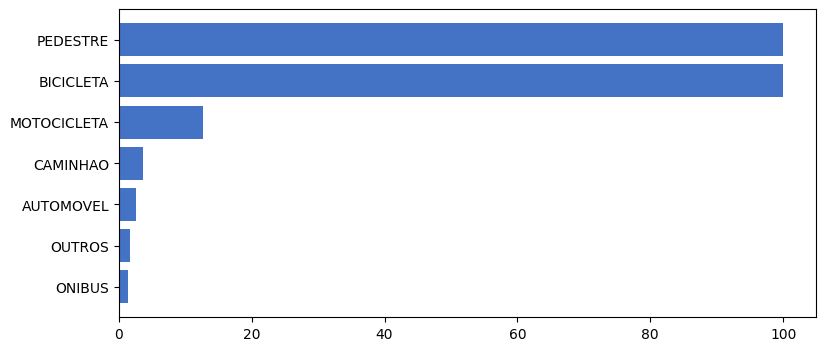

In [7]:
variaveis_vulnerabilidade = [
    "modo_transporte_vitima", "faixa_etaria_analise", "sexo", "tipo_via",
    *COLUNAS_TIPO_DETALHADO.keys(),
]
frequencias_vulnerabilidade = {}
residuos_vulnerabilidade = {}
testes_vulnerabilidade = []
for variavel in variaveis_vulnerabilidade:
    frequencias, residuos, teste = analisar_tabela_contingencia(
        pessoas_analise, variavel, "lesao_grave_ou_fatal"
    )
    frequencias_vulnerabilidade[variavel] = frequencias
    residuos_vulnerabilidade[variavel] = residuos
    testes_vulnerabilidade.append(teste)
    print(f"\nFrequências e percentuais por {variavel}")
    print(frequencias)
    if residuos.height:
        print(f"Resíduos ajustados por {variavel}; |resíduo| > 1,96 é referência exploratória")
        print(residuos.sort("residuo_ajustado", descending=True))

testes_vulnerabilidade = pl.DataFrame(testes_vulnerabilidade)
print(testes_vulnerabilidade.sort("p_valor", nulls_last=True))
grafico_percentuais(
    frequencias_vulnerabilidade["modo_transporte_vitima"],
    "modo_transporte_vitima", "lesao_grave_ou_fatal",
    titulo="Lesão grave ou fatal por modo de transporte",
)
interpretar_associacao(testes_vulnerabilidade, "Vulnerabilidade das vítimas")

**Limitações e redação para o TCC:** a classificação de gravidade pode estar ausente ou ser divergente entre tabelas; vítimas do mesmo sinistro não são observações necessariamente independentes, de modo que os intervalos e testes simples podem subestimar a incerteza. As comparações não ajustadas são exploratórias e não devem ser descritas como efeitos do modo de transporte ou de características pessoais.

## 6. Análise 2 — Regressão logística para óbito da vítima

**Justificativa:** o desfecho é óbito individual (`gravidade_lesao == FATAL`), modelado entre vítimas com classificação conhecida. Os preditores incluem modo de transporte, sexo, idade, município, tipo de via e indicadores de sinistro detalhado. A idade é expressa por década, centrada na média. O modelo estima associações condicionais, não causalidade. Categorias de referência são declaradas abaixo.

In [ ]:
preditores_categoricos = ["modo_transporte_vitima", "sexo", "municipio", "tipo_via"]
colunas_modelo = [
    "obito", "idade_anos", *preditores_categoricos,
    *COLUNAS_TIPO_DETALHADO.keys(),
]
base_modelo = pessoas_analise.select(colunas_modelo).drop_nulls(
    subset=["obito", "idade_anos", *preditores_categoricos]
).filter(
    pl.col("idade_anos").is_between(0, 110)
    & (pl.col("modo_transporte_vitima") != VALOR_DESCONHECIDO)
    & (pl.col("sexo") != VALOR_DESCONHECIDO)
    & (pl.col("municipio") != VALOR_DESCONHECIDO)
    & (pl.col("tipo_via") != VALOR_DESCONHECIDO)
)
base_modelo_pd = base_modelo.to_pandas()
base_modelo_pd["obito"] = base_modelo_pd["obito"].astype(int)
base_modelo_pd["idade_por_10_anos"] = (
    base_modelo_pd["idade_anos"] - base_modelo_pd["idade_anos"].mean()
) / 10
referencias_modelo = {
    "modo_transporte_vitima": "AUTOMOVEL",
    "sexo": "FEMININO",
    "municipio": "CAMPINAS",
    "tipo_via": "URBANO",
}
for variavel, referencia in referencias_modelo.items():
    if referencia not in set(base_modelo_pd[variavel]):
        raise ValueError(f"Referência {referencia} não encontrada em {variavel}.")
    base_modelo_pd[variavel] = pd.Categorical(
        base_modelo_pd[variavel],
        categories=[referencia] + sorted(set(base_modelo_pd[variavel]) - {referencia}),
    )
termos_tipo = [
    nome for nome in COLUNAS_TIPO_DETALHADO
    if base_modelo_pd[nome].nunique(dropna=True) > 1
]
formula_obito = (
    "obito ~ C(modo_transporte_vitima) + C(sexo) + idade_por_10_anos + "
    "C(municipio) + C(tipo_via)"
    + (" + " + " + ".join(termos_tipo) if termos_tipo else "")
)
modelo_obito = glm(
    formula=formula_obito,
    data=base_modelo_pd,
    family=Binomial(),
).fit()
intervalos_modelo = modelo_obito.conf_int()
resultados_modelo = pl.DataFrame([
    {
        "termo": termo,
        "odds_ratio": float(np.exp(coeficiente)),
        "ic95_inf": float(np.exp(intervalos_modelo.loc[termo, 0])),
        "ic95_sup": float(np.exp(intervalos_modelo.loc[termo, 1])),
        "p_valor": float(modelo_obito.pvalues.loc[termo]),
    }
    for termo, coeficiente in modelo_obito.params.items()
])
print(f"N do modelo: {len(base_modelo_pd):,}; óbitos: {int(base_modelo_pd['obito'].sum()):,}")
print("Categorias de referência:", referencias_modelo)
print(resultados_modelo.filter(pl.col("termo") != "Intercept").sort("p_valor"))

resultados_grafico = resultados_modelo.filter(pl.col("termo") != "Intercept").sort("odds_ratio")
if resultados_grafico.height:
    figura, eixo = plt.subplots(figsize=(10, max(5, resultados_grafico.height * 0.38)))
    ordenados = resultados_grafico.to_dicts()
    valores = np.array([linha["odds_ratio"] for linha in ordenados])
    eixo.errorbar(
        valores, np.arange(len(ordenados)),
        xerr=[valores - np.array([linha["ic95_inf"] for linha in ordenados]),
              np.array([linha["ic95_sup"] for linha in ordenados]) - valores],
        fmt="o", capsize=3,
    )
    eixo.set_yticks(np.arange(len(ordenados)), [linha["termo"] for linha in ordenados])
    eixo.axvline(1, color="red", linestyle="--")
    eixo.set_xscale("log")
    eixo.set_xlabel("Odds Ratio e IC95% (escala logarítmica)")
    eixo.set_title("Fatores associados ao óbito da vítima")
    figura.tight_layout()
    plt.show()
print("Interpretação: OR acima de 1 indica maiores odds observadas em relação à categoria de referência, condicionado às covariáveis do modelo; não é razão de riscos nem evidência causal.")

**Limitações e redação para o TCC:** o modelo pode sofrer confusão residual, dependência entre vítimas do mesmo sinistro, separação em categorias raras e viés de seleção decorrente de dados faltantes. IC95% assintótico e p-valores dependem das premissas do modelo. As estimativas devem ser reportadas como associações ajustadas, com referência explícita às categorias e sem linguagem causal.

## 7. Análise 3 — Tipos detalhados de sinistro

**Justificativa:** cada indicador de tipo detalhado é avaliado no nível do sinistro; um evento pode apresentar mais de um indicador, portanto as categorias não são mutuamente exclusivas. A gravidade é operacionalizada como registro fatal (`tipo_registro == SINISTRO FATAL`) e comparada com os demais sinistros elegíveis. OR não ajustado compara odds de sinistro fatal entre registros com e sem o indicador; zeros recebem correção de 0,5 e teste exato de Fisher.

In [ ]:
def marcador_sinistro(colunas: list[str]) -> pl.Expr:
    existentes = [coluna for coluna in colunas if coluna in sinistros.columns]
    return pl.any_horizontal([
        pl.col(coluna).cast(pl.String, strict=False).str.strip_chars().str.to_uppercase()
        .is_in(["S", "SIM", "1", "TRUE"]).fill_null(False)
        for coluna in existentes
    ]) if existentes else pl.lit(False)

sinistros_detalhados = sinistros.with_columns(
    (pl.col("tipo_registro") == "SINISTRO FATAL").alias("sinistro_fatal"),
    *[marcador_sinistro(colunas).alias(nome) for nome, colunas in COLUNAS_TIPO_DETALHADO.items()],
)
linhas_tipos = []
for nome, colunas in COLUNAS_TIPO_DETALHADO.items():
    exposto = sinistros_detalhados.filter(pl.col(nome))
    nao_exposto = sinistros_detalhados.filter(~pl.col(nome))
    fatais_expostos = exposto.filter(pl.col("sinistro_fatal")).height
    nao_fatais_expostos = exposto.height - fatais_expostos
    fatais_nao_expostos = nao_exposto.filter(pl.col("sinistro_fatal")).height
    nao_fatais_nao_expostos = nao_exposto.height - fatais_nao_expostos
    tabela_2x2 = np.array([[fatais_expostos, nao_fatais_expostos],
                          [fatais_nao_expostos, nao_fatais_nao_expostos]])
    correção = 0.5 if np.any(tabela_2x2 == 0) else 0
    tabela_corrigida = tabela_2x2 + correção
    or_bruto = (tabela_corrigida[0, 0] * tabela_corrigida[1, 1]) / (
        tabela_corrigida[0, 1] * tabela_corrigida[1, 0]
    )
    erro_padrao_log_or = np.sqrt(np.sum(1 / tabela_corrigida))
    inferior = np.exp(np.log(or_bruto) - 1.96 * erro_padrao_log_or)
    superior = np.exp(np.log(or_bruto) + 1.96 * erro_padrao_log_or)
    p_fisher = stats.fisher_exact(tabela_2x2).pvalue
    ic_prop = proportion_confint(fatais_expostos, exposto.height, method="wilson") if exposto.height else (None, None)
    linhas_tipos.append({
        "tipo_detalhado": nome, "sinistros_com_tipo": exposto.height,
        "fatais_com_tipo": fatais_expostos,
        "percentual_fatal_com_tipo": 100 * fatais_expostos / exposto.height if exposto.height else None,
        "ic95_inf_percentual": 100 * ic_prop[0] if ic_prop[0] is not None else None,
        "ic95_sup_percentual": 100 * ic_prop[1] if ic_prop[1] is not None else None,
        "odds_ratio": float(or_bruto), "ic95_inf_or": float(inferior),
        "ic95_sup_or": float(superior), "p_valor_fisher": float(p_fisher),
    })
resultados_tipos_detalhados = pl.DataFrame(linhas_tipos).sort("sinistros_com_tipo", descending=True)
print(resultados_tipos_detalhados)
figura, eixo = plt.subplots(figsize=(9, 5))
dados_grafico = resultados_tipos_detalhados.sort("percentual_fatal_com_tipo")
eixo.barh(dados_grafico["tipo_detalhado"].to_list(), dados_grafico["percentual_fatal_com_tipo"].to_list(), color="#70AD47")
eixo.set_xlabel("Sinistros fatais entre os registros com tipo (%)")
eixo.set_title("Frequência e gravidade por tipo detalhado de sinistro")
figura.tight_layout()
plt.show()
print("Texto para o TCC: Os tipos detalhados foram tratados como indicadores não exclusivos. As diferenças de frequência e odds observadas descrevem associações entre os registros disponíveis e não devem ser interpretadas como efeitos causais nem como riscos populacionais.")

**Limitações:** os campos detalhados são indicadores do sinistro e podem estar ausentes ou subnotificados. O grupo de comparação inclui sinistros sem o indicador em questão e não representa necessariamente uma categoria mecanicamente distinta. Os OR são brutos, sujeitos a confundimento e à baixa frequência de algumas combinações.

## 8. Análise 4 — Local do óbito

**Justificativa:** a unidade é a vítima fatal. O local do óbito é comparado entre modo de transporte, faixa etária e tipo de via. O número de óbitos por local é apresentado com o percentual dentro de cada grupo; não deve ser interpretado como probabilidade individual de óbito.

Distribuição do local do óbito por modo_transporte_vitima
shape: (28, 7)
┌───────────────────┬───────────────────┬─────────┬─────┬──────────────────┬───────────┬───────────┐
│ modo_transporte_v ┆ local_obito       ┆ n_grupo ┆ n   ┆ percentual_no_gr ┆ ic95_inf  ┆ ic95_sup  │
│ itima             ┆ ---               ┆ ---     ┆ --- ┆ upo              ┆ ---       ┆ ---       │
│ ---               ┆ str               ┆ i64     ┆ i64 ┆ ---              ┆ f64       ┆ f64       │
│ str               ┆                   ┆         ┆     ┆ f64              ┆           ┆           │
╞═══════════════════╪═══════════════════╪═════════╪═════╪══════════════════╪═══════════╪═══════════╡
│ AUTOMOVEL         ┆ ESTABELECIMENTO   ┆ 188     ┆ 87  ┆ 46.276596        ┆ 39.295073 ┆ 53.407235 │
│                   ┆ DE SAUDE          ┆         ┆     ┆                  ┆           ┆           │
│ AUTOMOVEL         ┆ NAO INFORMADO     ┆ 188     ┆ 2   ┆ 1.06383          ┆ 0.292227  ┆ 3.795241  │
│ AUTOMOVEL       

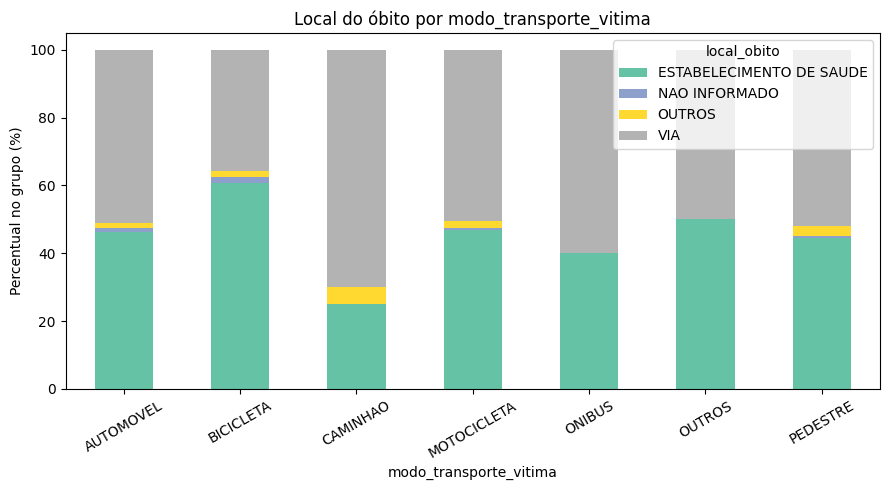

Distribuição do local do óbito por faixa_etaria_analise
shape: (20, 7)
┌───────────────────┬───────────────────┬─────────┬─────┬──────────────────┬───────────┬───────────┐
│ faixa_etaria_anal ┆ local_obito       ┆ n_grupo ┆ n   ┆ percentual_no_gr ┆ ic95_inf  ┆ ic95_sup  │
│ ise               ┆ ---               ┆ ---     ┆ --- ┆ upo              ┆ ---       ┆ ---       │
│ ---               ┆ str               ┆ i64     ┆ i64 ┆ ---              ┆ f64       ┆ f64       │
│ str               ┆                   ┆         ┆     ┆ f64              ┆           ┆           │
╞═══════════════════╪═══════════════════╪═════════╪═════╪══════════════════╪═══════════╪═══════════╡
│ 00-17             ┆ ESTABELECIMENTO   ┆ 45      ┆ 25  ┆ 55.555556        ┆ 41.176134 ┆ 69.06107  │
│                   ┆ DE SAUDE          ┆         ┆     ┆                  ┆           ┆           │
│ 00-17             ┆ NAO INFORMADO     ┆ 45      ┆ 0   ┆ 0.0              ┆ 0.0       ┆ 7.86516   │
│ 00-17             

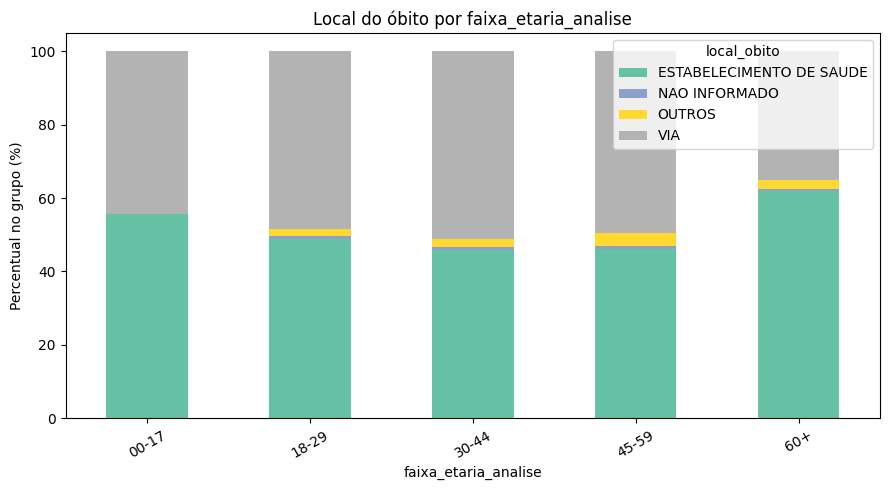

Distribuição do local do óbito por tipo_via
shape: (8, 7)
┌──────────────┬─────────────────────┬─────────┬─────┬─────────────────────┬───────────┬───────────┐
│ tipo_via     ┆ local_obito         ┆ n_grupo ┆ n   ┆ percentual_no_grupo ┆ ic95_inf  ┆ ic95_sup  │
│ ---          ┆ ---                 ┆ ---     ┆ --- ┆ ---                 ┆ ---       ┆ ---       │
│ str          ┆ str                 ┆ i64     ┆ i64 ┆ f64                 ┆ f64       ┆ f64       │
╞══════════════╪═════════════════════╪═════════╪═════╪═════════════════════╪═══════════╪═══════════╡
│ ESTRADAS E   ┆ ESTABELECIMENTO DE  ┆ 544     ┆ 168 ┆ 30.882353           ┆ 27.145337 ┆ 34.887474 │
│ RODOVIAS     ┆ SAUDE               ┆         ┆     ┆                     ┆           ┆           │
│ ESTRADAS E   ┆ NAO INFORMADO       ┆ 544     ┆ 0   ┆ 0.0                 ┆ 0.0       ┆ 0.701199  │
│ RODOVIAS     ┆                     ┆         ┆     ┆                     ┆           ┆           │
│ ESTRADAS E   ┆ OUTROS          

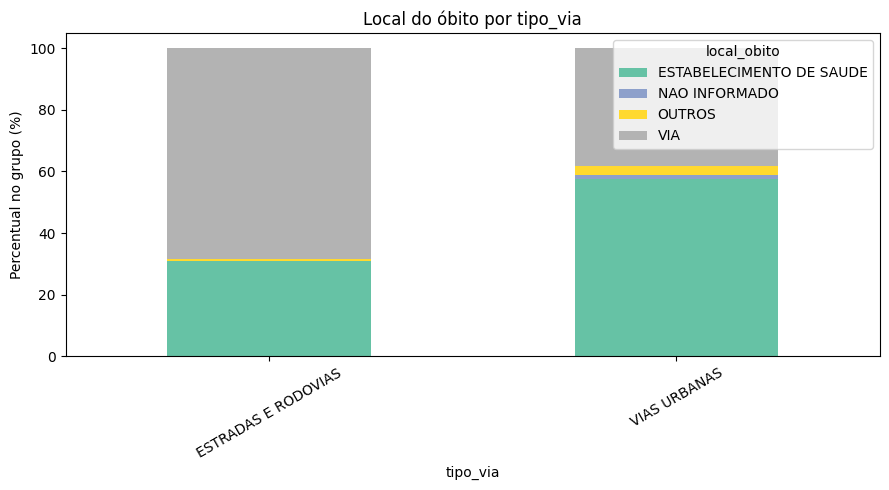

shape: (3, 8)
┌─────────────────┬──────┬────────────┬─────┬────────────┬──────────┬─────────────────┬────────────┐
│ variavel        ┆ n    ┆ qui2       ┆ gl  ┆ p_valor    ┆ v_cramer ┆ celulas_esperad ┆ status     │
│ ---             ┆ ---  ┆ ---        ┆ --- ┆ ---        ┆ ---      ┆ as_menor_5_pct  ┆ ---        │
│ str             ┆ i64  ┆ f64        ┆ i64 ┆ f64        ┆ f64      ┆ ---             ┆ str        │
│                 ┆      ┆            ┆     ┆            ┆          ┆ f64             ┆            │
╞═════════════════╪══════╪════════════╪═════╪════════════╪══════════╪═════════════════╪════════════╡
│ modo_transporte ┆ 1198 ┆ 12.896542  ┆ 18  ┆ 0.797682   ┆ 0.059903 ┆ 57.142857       ┆ verificar  │
│ _vitima         ┆      ┆            ┆     ┆            ┆          ┆                 ┆ frequência │
│                 ┆      ┆            ┆     ┆            ┆          ┆                 ┆ esperada;… │
│ faixa_etaria_an ┆ 1136 ┆ 16.802702  ┆ 12  ┆ 0.157171   ┆ 0.070217 ┆ 40.0   

In [8]:
vitimas_fatais_local = pessoas_analise.filter(pl.col("obito") == True).with_columns(
    texto_categorico("local_obito").alias("local_obito")
)
frequencias_local_obito = {}
testes_local_obito = []
for variavel in ["modo_transporte_vitima", "faixa_etaria_analise", "tipo_via"]:
    frequencias, residuos, teste = analisar_tabela_contingencia(
        vitimas_fatais_local, variavel, "local_obito"
    )
    frequencias_local_obito[variavel] = frequencias
    testes_local_obito.append(teste)
    print(f"Distribuição do local do óbito por {variavel}")
    print(frequencias)
    pivote = frequencias.to_pandas().pivot(
        index=variavel, columns="local_obito", values="percentual_no_grupo"
    ).fillna(0)
    eixo = pivote.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="Set2")
    eixo.set_ylabel("Percentual no grupo (%)")
    eixo.set_title(f"Local do óbito por {variavel}")
    eixo.tick_params(axis="x", labelrotation=30)
    eixo.figure.tight_layout()
    plt.show()
testes_local_obito = pl.DataFrame(testes_local_obito)
print(testes_local_obito)
interpretar_associacao(testes_local_obito, "Local do óbito")

**Limitações e redação para o TCC:** a análise é condicionada à existência de registro de óbito e de local preenchido. Categorias desconhecidas são explicitadas e excluídas do teste de associação. As diferenças descrevem a distribuição dos locais informados entre vítimas fatais; não permitem inferir acesso, qualidade da assistência ou causalidade.

## 9. Análise 5 — Tempo entre sinistro e óbito

**Justificativa:** restringe-se às vítimas classificadas como fatais com tempo numérico não negativo. Comparam-se pedestres, motociclistas, ciclistas e ocupantes de automóvel por mediana, quartis e Kruskal–Wallis. O tamanho de efeito reportado é epsilon-quadrado. A unidade do campo deve ser confirmada no dicionário da extração antes da redação final; os rótulos abaixo mantêm a unidade armazenada como recebida.

shape: (4, 9)
┌────────────────────────┬─────┬──────────┬───────────────┬───┬─────┬──────┬────────┬────────┐
│ modo_transporte_vitima ┆ n   ┆ media    ┆ desvio_padrao ┆ … ┆ q1  ┆ q3   ┆ minimo ┆ maximo │
│ ---                    ┆ --- ┆ ---      ┆ ---           ┆   ┆ --- ┆ ---  ┆ ---    ┆ ---    │
│ str                    ┆ i64 ┆ f64      ┆ f64           ┆   ┆ f64 ┆ f64  ┆ f64    ┆ f64    │
╞════════════════════════╪═════╪══════════╪═══════════════╪═══╪═════╪══════╪════════╪════════╡
│ PEDESTRE               ┆ 348 ┆ 1.807471 ┆ 4.767233      ┆ … ┆ 0.0 ┆ 0.0  ┆ 0.0    ┆ 29.0   │
│ MOTOCICLETA            ┆ 575 ┆ 1.445217 ┆ 3.821365      ┆ … ┆ 0.0 ┆ 1.0  ┆ 0.0    ┆ 28.0   │
│ BICICLETA              ┆ 56  ┆ 3.214286 ┆ 5.901354      ┆ … ┆ 0.0 ┆ 4.25 ┆ 0.0    ┆ 26.0   │
│ AUTOMOVEL              ┆ 188 ┆ 1.819149 ┆ 4.929368      ┆ … ┆ 0.0 ┆ 0.25 ┆ 0.0    ┆ 27.0   │
└────────────────────────┴─────┴──────────┴───────────────┴───┴─────┴──────┴────────┴────────┘
shape: (1, 8)
┌────────────────┬────

C:\Users\aliss\AppData\Local\Temp\ipykernel_23912\3036214426.py:44: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  eixo.boxplot(amostras_tempo, labels=modos_incluidos, showfliers=False)


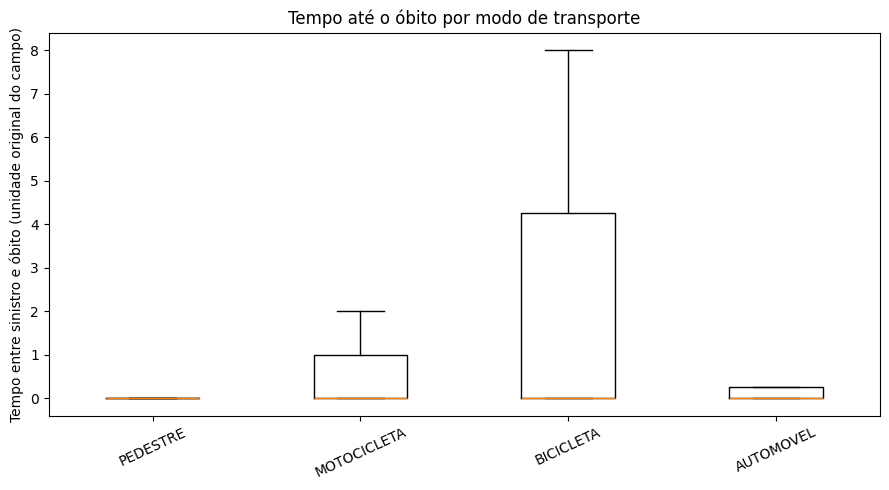

Texto para o TCC: O tempo registrado entre sinistro e óbito foi comparado entre os modos de transporte por teste de Kruskal–Wallis, com estatísticas descritivas e tamanho de efeito. A análise está condicionada às vítimas fatais com tempo preenchido e não permite atribuição causal.


In [9]:
modos_tempo_obito = ["PEDESTRE", "MOTOCICLETA", "BICICLETA", "AUTOMOVEL"]
dados_tempo_obito = vitimas_fatais_local.with_columns(
    pl.col("tempo_sinistro_obito").cast(pl.Float64, strict=False).alias("tempo_ate_obito")
).filter(
    pl.col("modo_transporte_vitima").is_in(modos_tempo_obito)
    & pl.col("tempo_ate_obito").is_not_null()
    & (pl.col("tempo_ate_obito") >= 0)
)
linhas_descritivas = []
amostras_tempo = []
modos_incluidos = []
for modo in modos_tempo_obito:
    valores = dados_tempo_obito.filter(pl.col("modo_transporte_vitima") == modo)["tempo_ate_obito"].to_numpy()
    if valores.size == 0:
        continue
    modos_incluidos.append(modo)
    amostras_tempo.append(valores)
    linhas_descritivas.append({
        "modo_transporte_vitima": modo, "n": int(valores.size),
        "media": float(np.mean(valores)),
        "desvio_padrao": float(np.std(valores, ddof=1)) if valores.size > 1 else None,
        "mediana": float(np.median(valores)),
        "q1": float(np.quantile(valores, 0.25)), "q3": float(np.quantile(valores, 0.75)),
        "minimo": float(np.min(valores)), "maximo": float(np.max(valores)),
    })
estatisticas_tempo_obito = pl.DataFrame(linhas_descritivas)
print(estatisticas_tempo_obito)
if len(amostras_tempo) >= 2:
    estatistica_kw, p_kw = stats.kruskal(*amostras_tempo)
    n_tempo = sum(len(amostra) for amostra in amostras_tempo)
    epsilon_quadrado = max(0.0, (estatistica_kw - len(amostras_tempo) + 1) / (n_tempo - len(amostras_tempo)))
    resultado_kw = pl.DataFrame([{
        "teste": "Kruskal-Wallis", "n": n_tempo, "grupos": len(amostras_tempo),
        "h": float(estatistica_kw), "gl": len(amostras_tempo) - 1,
        "p_valor": float(p_kw), "epsilon_quadrado": float(epsilon_quadrado),
        "grupos_incluidos": ", ".join(modos_incluidos),
    }])
else:
    resultado_kw = pl.DataFrame([{"teste": "Kruskal-Wallis", "n": dados_tempo_obito.height,
                                  "grupos": len(amostras_tempo), "status": "menos de dois grupos com observações"}])
print(resultado_kw)
if amostras_tempo:
    figura, eixo = plt.subplots(figsize=(9, 5))
    eixo.boxplot(amostras_tempo, labels=modos_incluidos, showfliers=False)
    eixo.set_ylabel("Tempo entre sinistro e óbito (unidade original do campo)")
    eixo.set_title("Tempo até o óbito por modo de transporte")
    eixo.tick_params(axis="x", labelrotation=25)
    figura.tight_layout()
    plt.show()
print("Texto para o TCC: O tempo registrado entre sinistro e óbito foi comparado entre os modos de transporte por teste de Kruskal–Wallis, com estatísticas descritivas e tamanho de efeito. A análise está condicionada às vítimas fatais com tempo preenchido e não permite atribuição causal.")

**Limitações:** valores ausentes, inconsistências na unidade ou arredondamento no tempo podem afetar a comparação. Kruskal–Wallis testa diferenças de distribuição e, isoladamente, não identifica quais pares diferem. Não se trata de tempo de sobrevivência censurado; mortes não observadas no registro e tempos ausentes podem introduzir viés.

## 10. Análise 6 — Complexidade do sinistro

**Justificativa:** unidade de análise: sinistro. A complexidade é resumida pelo total de veículos registrados e pela presença de motocicleta, caminhão, ônibus e bicicleta. Os registros de pedestres não são contados como veículos; bicicleta é mantida na soma de veículos e também como indicador de presença. A gravidade do sinistro é definida pela ocorrência de fatalidade ou lesão grave registrada. Campos de quantidade ausentes são tratados como zero para os indicadores, premissa que deve ser confrontada com o processo de preenchimento da base.

shape: (11, 7)
┌─────────────────┬───────────┬─────────────┬─────────────────┬────────────┬───────────┬───────────┐
│ indicador       ┆ categoria ┆ n_sinistros ┆ sinistros_grave ┆ percentual ┆ ic95_inf  ┆ ic95_sup  │
│ ---             ┆ ---       ┆ ---         ┆ s_ou_fatais     ┆ ---        ┆ ---       ┆ ---       │
│ str             ┆ str       ┆ i64         ┆ ---             ┆ f64        ┆ f64       ┆ f64       │
│                 ┆           ┆             ┆ i64             ┆            ┆           ┆           │
╞═════════════════╪═══════════╪═════════════╪═════════════════╪════════════╪═══════════╪═══════════╡
│ faixa_total_vei ┆ 1         ┆ 9205        ┆ 1576            ┆ 17.12113   ┆ 16.365356 ┆ 17.904335 │
│ culos           ┆           ┆             ┆                 ┆            ┆           ┆           │
│ faixa_total_vei ┆ 2         ┆ 14034       ┆ 1548            ┆ 11.030355  ┆ 10.52269  ┆ 11.559348 │
│ culos           ┆           ┆             ┆                 ┆            ┆

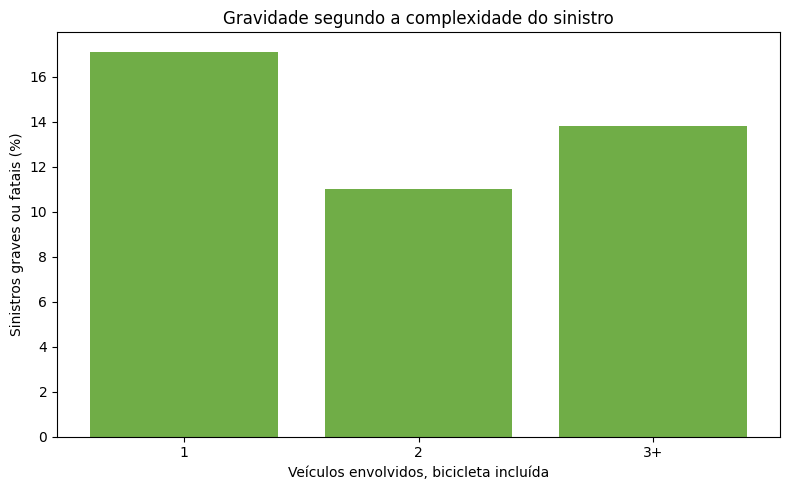

Texto para o TCC: A complexidade foi descrita pelo total de veículos e pela presença de tipos selecionados. As proporções e OR representam associação no nível do sinistro, não risco individual ou efeito causal. Campos de quantidade ausentes foram tratados como zero e essa premissa precisa ser considerada na interpretação.


In [13]:
colunas_contagem_veiculos = [
    "qtd_bicicleta", "qtd_motocicleta", "qtd_automovel", "qtd_onibus",
    "qtd_caminhao", "qtd_veic_outros", "qtd_veic_nao_disponivel",
]
contagens = [pl.col(coluna).cast(pl.Float64, strict=False).fill_null(0) for coluna in colunas_contagem_veiculos]
sinistros_complexidade = sinistros.with_columns(
    *[pl.col(coluna).cast(pl.Float64, strict=False).fill_null(0).alias(coluna) for coluna in colunas_contagem_veiculos],
    pl.col("qtd_gravidade_fatal").cast(pl.Float64, strict=False).fill_null(0).alias("qtd_gravidade_fatal"),
    pl.col("qtd_gravidade_grave").cast(pl.Float64, strict=False).fill_null(0).alias("qtd_gravidade_grave"),
).with_columns(
    pl.sum_horizontal(contagens).alias("total_veiculos_envolvidos"),
    ((pl.col("qtd_gravidade_fatal") > 0) | (pl.col("qtd_gravidade_grave") > 0)
     | (pl.col("tipo_registro") == "SINISTRO FATAL")).alias("sinistro_grave_ou_fatal"),
    (pl.col("qtd_motocicleta") > 0).alias("presenca_motocicleta"),
    (pl.col("qtd_caminhao") > 0).alias("presenca_caminhao"),
    (pl.col("qtd_onibus") > 0).alias("presenca_onibus"),
    (pl.col("qtd_bicicleta") > 0).alias("presenca_bicicleta"),
).with_columns(
    pl.when(pl.col("total_veiculos_envolvidos") == 0).then(pl.lit("0"))
    .when(pl.col("total_veiculos_envolvidos") == 1).then(pl.lit("1"))
    .when(pl.col("total_veiculos_envolvidos") == 2).then(pl.lit("2"))
    .otherwise(pl.lit("3+")).alias("faixa_total_veiculos")
)
linhas_complexidade = []
testes_complexidade = []
for variavel in ["faixa_total_veiculos", "presenca_motocicleta", "presenca_caminhao", "presenca_onibus", "presenca_bicicleta"]:
    base_contingencia = sinistros_complexidade.with_columns(
        pl.col(variavel).cast(pl.String).alias("categoria_complexidade"),
        pl.col("sinistro_grave_ou_fatal").cast(pl.String).alias("gravidade_binaria"),
    )
    frequencias, _, teste = analisar_tabela_contingencia(
        base_contingencia, "categoria_complexidade", "gravidade_binaria", excluir_desconhecido=False
    )
    teste["indicador"] = variavel
    testes_complexidade.append(teste)
    for linha in frequencias.filter(
        pl.col("gravidade_binaria").str.to_lowercase() == "true"
    ).to_dicts():
        linhas_complexidade.append({
            "indicador": variavel, "categoria": linha["categoria_complexidade"],
            "n_sinistros": linha["n_grupo"], "sinistros_graves_ou_fatais": linha["n"],
            "percentual": linha["percentual_no_grupo"],
            "ic95_inf": linha["ic95_inf"], "ic95_sup": linha["ic95_sup"],
        })
resultados_complexidade = pl.DataFrame(linhas_complexidade)
print(resultados_complexidade)
testes_complexidade = pl.DataFrame(testes_complexidade)
print(testes_complexidade)

# OR bruto para presença/ausência de cada tipo de veículo.
linhas_or_complexidade = []
for variavel in ["presenca_motocicleta", "presenca_caminhao", "presenca_onibus", "presenca_bicicleta"]:
    expostos = sinistros_complexidade.filter(pl.col(variavel))
    nao_expostos = sinistros_complexidade.filter(~pl.col(variavel))
    a = expostos.filter(pl.col("sinistro_grave_ou_fatal")).height
    b = expostos.height - a
    c = nao_expostos.filter(pl.col("sinistro_grave_ou_fatal")).height
    d = nao_expostos.height - c
    tabela_2x2 = np.array([[a, b], [c, d]])
    ajuste = 0.5 if np.any(tabela_2x2 == 0) else 0
    tabela_ajustada = tabela_2x2 + ajuste
    or_estimado = tabela_ajustada[0, 0] * tabela_ajustada[1, 1] / (tabela_ajustada[0, 1] * tabela_ajustada[1, 0])
    se_log = np.sqrt(np.sum(1 / tabela_ajustada))
    linhas_or_complexidade.append({
        "indicador": variavel, "odds_ratio": float(or_estimado),
        "ic95_inf": float(np.exp(np.log(or_estimado) - 1.96 * se_log)),
        "ic95_sup": float(np.exp(np.log(or_estimado) + 1.96 * se_log)),
        "p_valor_fisher": float(stats.fisher_exact(tabela_2x2).pvalue),
    })
odds_ratios_complexidade = pl.DataFrame(linhas_or_complexidade)
print(odds_ratios_complexidade)

if resultados_complexidade.height:
    dados_grafico_complexidade = resultados_complexidade.filter(
        pl.col("indicador") == "faixa_total_veiculos"
    ).sort("categoria")
else:
    dados_grafico_complexidade = pl.DataFrame()

if dados_grafico_complexidade.height:
    figura, eixo = plt.subplots(figsize=(8, 5))
    eixo.bar(
        dados_grafico_complexidade["categoria"].to_list(),
        dados_grafico_complexidade["percentual"].to_numpy(),
        color="#70AD47",
    )
    eixo.set_ylabel("Sinistros graves ou fatais (%)")
    eixo.set_xlabel("Veículos envolvidos, bicicleta incluída")
    eixo.set_title("Gravidade segundo a complexidade do sinistro")
    figura.tight_layout()
    plt.show()
else:
    print("Não há categorias válidas de total de veículos para produzir o gráfico.")
print("Texto para o TCC: A complexidade foi descrita pelo total de veículos e pela presença de tipos selecionados. As proporções e OR representam associação no nível do sinistro, não risco individual ou efeito causal. Campos de quantidade ausentes foram tratados como zero e essa premissa precisa ser considerada na interpretação.")

**Limitações:** contagens de vítimas fatais e graves em nível de sinistro podem ter preenchimento incompleto; notificação foi excluída. Indicadores derivados de quantidades não distinguem ausência verdadeira de informação ausente. As comparações são brutas, não controlam fatores de confusão e não estimam risco por exposição.

## Síntese metodológica

Os resultados numéricos e os gráficos são produzidos pela execução das células anteriores nas bases locais. Antes de inserir resultados no TCC, registrar período, denominadores, número de observações analisadas, dados excluídos, estimativas com IC95%, tamanhos de efeito e pressupostos. Os parágrafos-modelo devem ser completados com valores observados após a execução e revisados à luz do dicionário da versão específica dos dados do Infosiga-SP.